In [1]:
import pandas as pd
import seaborn as sns
import pingouin as pg
import matplotlib.pyplot as plt
dataset = pd.read_csv('../data/doctor_result_data.csv')

/Users/root202/Software/anaconda3/envs/posthoc-eval/lib/python3.8/site-packages/outdated/utils.py:14: OutdatedPackageWarning: The package outdated is out of date. Your version is 0.2.1, the latest is 0.2.2.
Set the environment variable OUTDATED_IGNORE=1 to disable these warnings.
  return warn(
/Users/root202/Software/anaconda3/envs/posthoc-eval/lib/python3.8/site-packages/outdated/utils.py:14: OutdatedPackageWarning: The package pingouin is out of date. Your version is 0.5.1, the latest is 0.5.3.
Set the environment variable OUTDATED_IGNORE=1 to disable these warnings.
  return warn(


# Testing the hypothesis: the degree of plausibility is associated with whether doctor will take or reject AI decisions

- doctor_result_data.csv data is the study result dataset
- Outcome variable Y: doctor final prediction after checking explanation drXAI is agreeable with AI prediction
    - `dataset['Agreement_xai'] = dataset.apply(lambda row: "Agree" if row['AIpred'] == row['drXAI'] else "Disagree", axis = 1)`
- Treatment variable X: plausibility, xai_qual
- controlled variable Z: MRI_easiness = dr_acc. The raw data column 'MRI Difficulty' is just renamed from dr_acc, so should be called easiness.
- Causal diagram: MRI_easiness -> dr_agreement, MRI_easiness -> plausibility -> dr_agreement

```
dag {
"Dr agreement" [outcome,pos="-0.232,-0.809"]
"MRI easiness" [pos="-0.965,-0.798"]
Plausibility [exposure,pos="-0.618,-0.351"]
"MRI easiness" -> "Dr agreement"
"MRI easiness" -> Plausibility
Plausibility -> "Dr agreement"
}
```
Visualize the causal diagram at: https://www.dagitty.net/dags.html

## 1. data processing and stat. summary

In [2]:
# Get X, Y, Z data column from raw data
data = dataset[['Agreement_xai', 'xai_qual', 'MRI Difficulty']]
data = data.rename(columns={'xai_qual': 'Plausibility', 'MRI Difficulty': 'MRI_easiness'})
data = data.dropna()
data

,Agreement_xai,Plausibility,MRI_easiness
0,Agree,9.0,1.000000
1,Agree,10.0,1.000000
2,Agree,8.0,1.000000
3,Agree,7.0,1.000000
4,Agree,9.0,1.000000
...,...,...,...
754,Agree,0.0,0.870968
755,Agree,8.0,0.870968
756,Agree,3.0,0.870968
757,Agree,2.0,0.870968


In [3]:
# stat. summary of plausibility for group when doctor agree with AI
data[data['Agreement_xai']=="Agree"]['Plausibility'].describe()

count    649.000000
mean       6.453005
std        2.816622
min        0.000000
25%        5.000000
50%        7.000000
75%        9.000000
max       10.000000
Name: Plausibility, dtype: float64

In [4]:
# stat. summary of plausibility for group when doctor disagreeagree with AI
data[data['Agreement_xai']=="Disagree"]['Plausibility'].describe()

count    95.000000
mean      3.821053
std       2.559833
min       0.000000
25%       2.000000
50%       4.000000
75%       5.500000
max      10.000000
Name: Plausibility, dtype: float64

/Users/root202/Software/anaconda3/envs/posthoc-eval/lib/python3.8/site-packages/outdated/utils.py:14: OutdatedPackageWarning: The package outdated is out of date. Your version is 0.2.1, the latest is 0.2.2.
Set the environment variable OUTDATED_IGNORE=1 to disable these warnings.
  return warn(
/Users/root202/Software/anaconda3/envs/posthoc-eval/lib/python3.8/site-packages/outdated/utils.py:14: OutdatedPackageWarning: The package pingouin is out of date. Your version is 0.5.1, the latest is 0.5.3.
Set the environment variable OUTDATED_IGNORE=1 to disable these warnings.
  return warn(


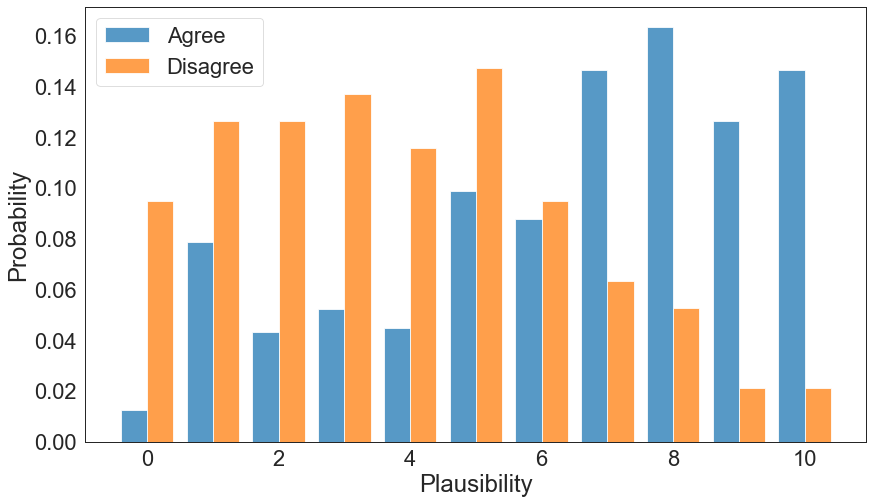

In [19]:
# visualize the plausibility distribution for the two groups
sns.set_style("white")
with sns.plotting_context("paper", font_scale=2.5):

    fig, ax = plt.subplots(figsize=(14,8))
    plt.grid(color='white',  zorder=2)


    g=sns.histplot(ax = ax, data=data, x="Plausibility", hue="Agreement_xai",discrete=True, stat="probability", common_norm=False, multiple="dodge", shrink=.8)#, stat="density")
    plt.xlabel("Plausibility")
    plt.ylabel("Probability")
    g.legend_.set_title(None)
    plt.savefig('../draft/plausibility_hist.pdf', bbox_inches = None)

## 2. Stat. test

In [4]:
# one side t-test: whether agree has higher xai_qual vs. disagree
agree = data[data['Agreement_xai']=="Agree"]['Plausibility'].to_list()
disagree = data[data['Agreement_xai']=="Disagree"]['Plausibility'].to_list()
# test for assumption of t-test: Homogeneity of Variances
pg.homoscedasticity([agree,disagree])

,W,pval,equal_var
levene,0.554367,0.456775,True


In [6]:
# test for assumption of t-test: normal distribution
pg.normality(agree), pg.normality(disagree)

(          W          pval  normal
 0  0.914885  1.269209e-18   False,
           W      pval  normal
 0  0.956661  0.003209   False)

In [10]:
# test of assumption for t-test failed on normality test, use nonparametric test instead
pg.ttest(x = agree, y = disagree, alternative = 'greater')

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,9.236328,129.678812,greater,3.193105e-16,"[2.16, inf]",0.94491,2.974e+16,1.0


In [11]:
# Mann–Whitney U test
pg.mwu(x = agree, y = disagree, alternative = 'greater')

,U-val,alternative,p-val,RBC,CLES
MWU,46533.0,greater,3.294012e-16,-0.509464,0.754732


## 3. Causal analysis

In [9]:
data['Agreement_xai'] = data['Agreement_xai'].replace({'Agree': 1, 'Disagree': 0})
data['Plausibility_binary'] = data['Plausibility'] >5
data['Plausibility_binary'][data['Plausibility'] > 5] = 1
data['Plausibility_binary'][data['Plausibility'] <= 5] = 0
data

<ipython-input-9-23becd8fc78e>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['Plausibility_binary'][data['Plausibility'] > 5] = 1
<ipython-input-9-23becd8fc78e>:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['Plausibility_binary'][data['Plausibility'] <= 5] = 0


,Agreement_xai,Plausibility,MRI_easiness,Plausibility_binary
0,1,9.0,1.000000,1
1,1,10.0,1.000000,1
2,1,8.0,1.000000,1
3,1,7.0,1.000000,1
4,1,9.0,1.000000,1
...,...,...,...,...
754,1,0.0,0.870968,0
755,1,8.0,0.870968,1
756,1,3.0,0.870968,0
757,1,2.0,0.870968,0


Logistic regression adjustment as an outcome model for $P(Y=1|X,Z)$

In [10]:
from sklearn.linear_model import LogisticRegression as LR
adj_set = {'MRI_easiness'}
x_var = 'Plausibility_binary'
y_var = 'Agreement_xai'
X = data[list(adj_set) + [x_var]]
y = data[y_var]
clf = LR(random_state=0).fit(X, y)
clf.coef_, clf.score(X,y)

(array([[2.19925395, 1.65659278]]), 0.8696236559139785)

$ATE = P(Y^1=1) - P(Y^0=1) =0.94-0.77=0.17$

In [11]:
X_0 = X.copy()
X_0[x_var] = 0
X_1 = X.copy()
X_1[x_var] = 1

P_0 = clf.predict_proba(X_0)
P_1 = clf.predict_proba(X_1)

P_1[:,1].mean(),P_0[:,1].mean(), P_1[:,1].mean()-P_0[:,1].mean()

(0.9410095547716161, 0.771288752720601, 0.16972080205101503)